## Set Paths

In [ ]:
paths_results = "results"
paths_datasets = "/Users/rashid/data/DS/Healthcare/Breast/CHSJ"

In [33]:
import cv2
import os

# Input and output folders
input_folder = r"C:/programming/pythonML/computerVision/Breast_cancer/datasets"

output_grayscale = r"C:/programming/pythonML/computerVision/Breast_cancer/processed/grayscale"
output_folder = r"C:/programming/pythonML/computerVision/Breast_cancer/processed/sekeletal"
os.makedirs(output_grayscale, exist_ok=True)

# Collect image files
image_files = [f for f in os.listdir(input_folder) if f.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp', '.tif'))]

# Exception if folder is empty
if not image_files:
    raise FileNotFoundError(f"No images found in folder: {input_folder}")

for filename in image_files:
    filepath = os.path.join(input_folder, filename)

    # Load image
    image = cv2.imread(filepath, cv2.IMREAD_UNCHANGED)
    if image is None:
        print(f"⚠️ Skipping unreadable file: {filename}")
        continue

    # Convert to grayscale if not already
    if len(image.shape) == 2 or (len(image.shape) == 3 and image.shape[2] == 1):
        gray_image = image
        print(f"{filename}: Already grayscale.")
    else:
        gray_image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
        print(f"{filename}: Converted to grayscale.")

    # Resize (150x200)
    gray_image = cv2.resize(gray_image, (150, 200), interpolation=cv2.INTER_AREA)

    # Save grayscale image
    save_path = os.path.join(output_grayscale, f"gray_{filename}")
    cv2.imwrite(save_path, gray_image)
    print(f"✅ Saved: {save_path}")

print("\nProcessing complete!")


20588046 (36).png: Converted to grayscale.
✅ Saved: C:/programming/pythonML/computerVision/Breast_cancer/processed/grayscale\gray_20588046 (36).png
20588046 (60).png: Converted to grayscale.
✅ Saved: C:/programming/pythonML/computerVision/Breast_cancer/processed/grayscale\gray_20588046 (60).png
20588190 (2).png: Converted to grayscale.
✅ Saved: C:/programming/pythonML/computerVision/Breast_cancer/processed/grayscale\gray_20588190 (2).png
20588536 (25).png: Converted to grayscale.
✅ Saved: C:/programming/pythonML/computerVision/Breast_cancer/processed/grayscale\gray_20588536 (25).png
20588536 (60).png: Converted to grayscale.
✅ Saved: C:/programming/pythonML/computerVision/Breast_cancer/processed/grayscale\gray_20588536 (60).png
22579730 (2).png: Converted to grayscale.
✅ Saved: C:/programming/pythonML/computerVision/Breast_cancer/processed/grayscale\gray_22579730 (2).png
22579730 (49).png: Converted to grayscale.
✅ Saved: C:/programming/pythonML/computerVision/Breast_cancer/processed/g

Saving results to: C:/programming/pythonML/computerVision/Breast_cancer/processed/vht/


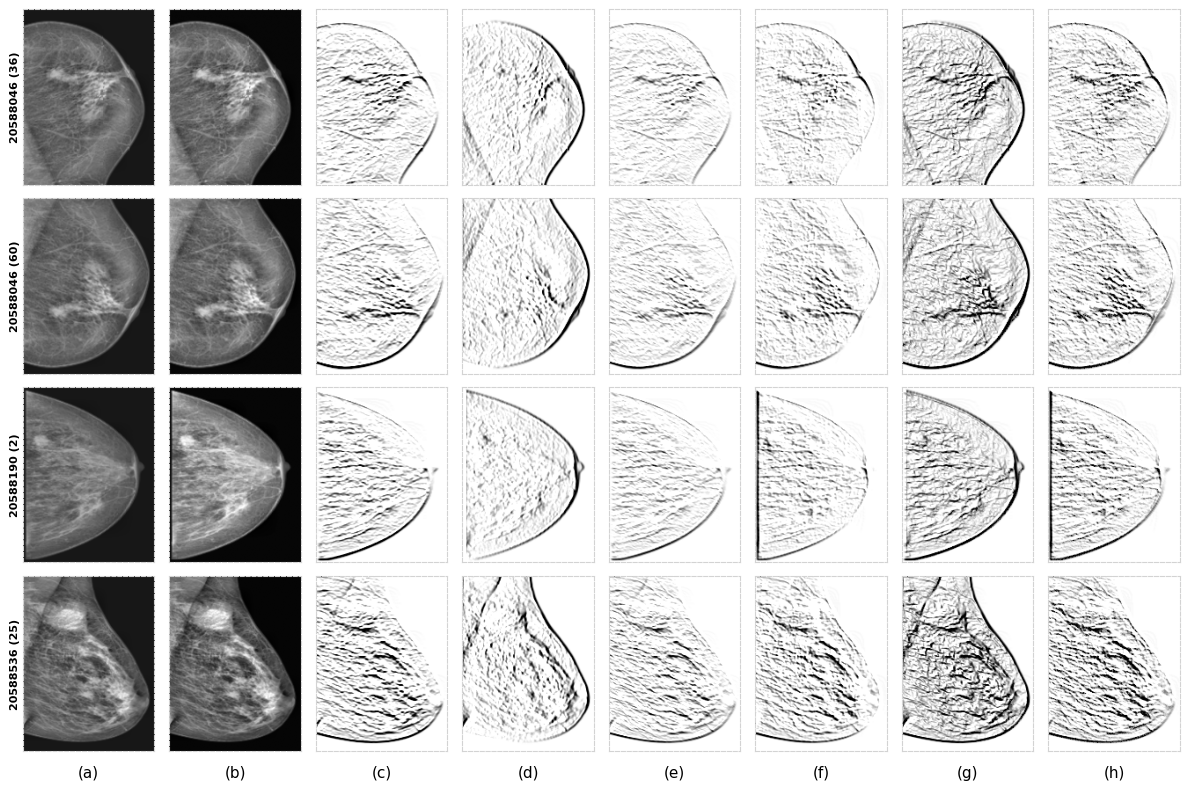

In [1]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Input & Output folders
input_folder = r"C:/programming/pythonML/computerVision/Breast_cancer/datasets"
output_folder = r"C:/programming/pythonML/computerVision/Breast_cancer/processed/vht/"
output_combined = r"C:/programming/pythonML/computerVision/Breast_cancer/processed/combined/"
os.makedirs(output_folder, exist_ok=True)

print("Saving results to:", output_folder)

# Collect image files
image_files = [f for f in os.listdir(input_folder) if f.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp', '.tif'))]
if not image_files:
    raise FileNotFoundError(f"No images found in folder: {input_folder}")

all_results = []

# Custom filters
edge_filter_45 = np.array([[ 2, 2, 0],
                           [-2, 0, 2],
                           [0, -2, -2]])
edge_filter_y = np.array([[2, 0, -2],
                          [2, 0, -2],
                          [2, 0, -2]])
edge_filter_135 = np.array([[0, 2, 2],
                            [-2, 0, 2],
                            [-2, -2, 0]])
edge_filter_x = np.array([[ 2,  2,  2],
                          [ 0,  0,  0],
                          [-2, -2, -2]])

# Loop through dataset
for filename in image_files:
    filepath = os.path.join(input_folder, filename)
    image = cv2.imread(filepath, cv2.IMREAD_COLOR)  # Load color
    if image is None:
        print(f"⚠️ Skipping unreadable file: {filename}")
        continue

    # Resize input image for consistency
    image_resized = cv2.resize(image, (150, 200), interpolation=cv2.INTER_AREA)

    # Convert to grayscale
    gray_image = cv2.cvtColor(image_resized, cv2.COLOR_BGR2GRAY)

    # ---- Edge detection using custom filters ----
    Edge_result_x = cv2.filter2D(gray_image, -1, edge_filter_x)
    Edge_result_y = cv2.filter2D(gray_image, -1, edge_filter_y)
    Edge_result_diag = cv2.filter2D(gray_image, -1, edge_filter_45)
    Edge_result_antidiag = cv2.filter2D(gray_image, -1, edge_filter_135)

    # Combine edges
    combined_xy = cv2.bitwise_or(Edge_result_x, Edge_result_y)
    combined_yx = cv2.bitwise_or(Edge_result_diag, Edge_result_antidiag)

    # 🔄 Processed set for visualization
    processed_set = [
        cv2.cvtColor(image_resized, cv2.COLOR_BGR2RGB),  # Original input in color
        gray_image,                                      # Grayscale
        cv2.bitwise_not(Edge_result_x),                  # X
        cv2.bitwise_not(Edge_result_y),                  # Y
        cv2.bitwise_not(Edge_result_diag),               # Diag
        cv2.bitwise_not(Edge_result_antidiag),           # Anti-Diag
        cv2.bitwise_not(combined_xy),                    # Combined XY
        cv2.bitwise_not(combined_yx)                     # Combined YX
    ]

    all_results.append(processed_set)

    # --- Save each variation in processed folder ---
    base_name, _ = os.path.splitext(filename)
    save_variations = {
        "Gray": gray_image,
        "Edge_vht_x": cv2.bitwise_not(Edge_result_x),
        "Edge_vht_y": cv2.bitwise_not(Edge_result_y),
        "Edge_vht_diag": cv2.bitwise_not(Edge_result_diag),
        "Edge_vht_antidiag": cv2.bitwise_not(Edge_result_antidiag),
        "Combined_xy": cv2.bitwise_not(combined_xy),
        "Combined_yx": cv2.bitwise_not(combined_yx)
    }
         
    for key, img in save_variations.items():
        out_path = os.path.join(output_folder, f"{base_name}_{key}.png")
        success = cv2.imwrite(out_path, img)

    cv2.imwrite(os.path.join(output_combined, f"{base_name}_xy.png"), cv2.bitwise_not(combined_xy))
    cv2.imwrite(os.path.join(output_combined, f"{base_name}_yx.png"), cv2.bitwise_not(combined_yx))

    
      #   if success:
      #       # print(f"✅ Saved: {out_path}")
      #   else:
      #       print(f"❌ Failed to save: {out_path}")


# --- Plot Grid (just first few for visualization) ---
cols = 8
rows = min(4, len(all_results))  # show max 4 images in grid
fig, axes = plt.subplots(rows, cols, figsize=(12, rows * 2))

# col_titles = ["Original", "Gray", "X-axis", "Y-axis", "Diag", "Anti-Diag", "Combined_xy", "Combined_yx"]

for r in range(rows):
    for c in range(cols):
        ax = axes[r, c] if rows > 1 else axes[c]
        if c == 0:
            ax.imshow(all_results[r][c])  # RGB color for original
        else:
            ax.imshow(all_results[r][c], cmap='gray')
        ax.set_xticks([]), ax.set_yticks([])
       
        # Light gray dashed axes
        for spine in ax.spines.values():
            spine.set_edgecolor("lightgray")
            spine.set_linestyle("--")
            spine.set_linewidth(0.8)
            
        # if r == 0:
        #     ax.set_title(col_titles[c], fontsize=9, pad=2)
        if c == 0:
            ax.set_ylabel(image_files[r], fontsize=8, rotation=90, labelpad=2, weight='bold')
            
        import string
labels = [f"({ch})" for ch in string.ascii_lowercase]

for r in range(rows):
    for c in range(cols):
        ax = axes[r, c] if rows > 1 else axes[c]

        # ✅ remove extension before using as ylabel
        if c == 0:
            # get filename without extension
            name_without_ext = os.path.splitext(image_files[r])[0]
            ax.set_ylabel(name_without_ext,
                          fontsize=8, rotation=90, labelpad=2, weight='bold')

        # ✅ Only add (a), (b), … under the last row
        if r == rows - 1:
            ax.set_xlabel(labels[c], fontsize=11, labelpad=10)


plt.tight_layout()
# Save the figure all in graphs folder
out_dir = r"C:/programming/pythonML/computerVision/Breast_cancer/processed/graphs"
os.makedirs(out_dir, exist_ok=True)

save_params = dict(dpi=300, transparent=True, bbox_inches='tight')
for ext in ["png", "pdf", "svg"]:
    plt.savefig(os.path.join(out_dir, f"Proposed NIVHT All Variations.{ext}"), **save_params)
plt.show()


In [49]:
# import os
# import cv2
# import numpy as np
# import matplotlib.pyplot as plt
# from skimage.morphology import skeletonize
# from skimage.util import img_as_ubyte

# # --- Paths ---
# combined_folder = r"C:/programming/pythonML/computerVision/Breast_cancer/processed/combined/"

# # Collect combined images
# combined_files = [f for f in os.listdir(combined_folder) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
# if not combined_files:
#     raise FileNotFoundError(f"No combined images found in: {combined_folder}")

# all_results = []

# # --- Process each combined image ---
# for filename in combined_files:
#     filepath = os.path.join(combined_folder, filename)
#     img = cv2.imread(filepath, cv2.IMREAD_GRAYSCALE)

#     if img is None:
#         print(f"⚠️ Skipping unreadable file: {filename}")
#         continue

#     title = os.path.splitext(filename)[0]
#     img = cv2.bitwise_not(img)

#     # --- Skeletonization ---
#     binary = img > 0
#     skeleton = skeletonize(binary)
#     thin_edges = img_as_ubyte(skeleton)

#     # --- Equalize histogram ---
#     img_eq = cv2.equalizeHist(img)

#     # --- Step 2: Threshold for high intensity ---
#     _, high_intensity = cv2.threshold(img_eq, 100, 255, cv2.THRESH_BINARY)

#     # --- Step 3: Extract edges (Canny) ---
#     edges = cv2.Canny(img, 50, 200)

#     # --- Step 4: Combine high-intensity mask with edges ---
#     combined_edges = cv2.bitwise_and(edges, high_intensity)

#     # Collect results
#     all_results.append((title, [cv2.bitwise_not(img), cv2.bitwise_not(thin_edges), cv2.bitwise_not(combined_edges)]))

# # --- Plot in grid ---
# ncols = 3  # Combined gray, skeleton, edges+intensity, connected
# nrows = len(all_results)
# count_rows = 5

# fig, axes = plt.subplots(nrows, ncols, figsize=(2 * ncols, 2 * nrows))

# for r, (title, result_set) in enumerate(all_results):
#     for c, img in enumerate(result_set):
#         ax = axes[r, c] if nrows > 1 else axes[c]

#         # Show grayscale or RGB image
#         if img.ndim == 2:
#             ax.imshow(img, cmap="gray")
#         else:
#             ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
#             ax.set_xticks([]), ax.set_yticks([])
       
#         # Light gray dashed axes
#         for spine in ax.spines.values():
#             spine.set_edgecolor("lightgray")
#             spine.set_linestyle("--")
#             spine.set_linewidth(0.8)

#         # Titles for top row
#         if r == 0:
#             ax.set_title(["Combined", "Skeleton", "NIVHT Edges", "Connected"][c],
#                          fontsize=10)

#         # Row labels
#         if c == 0:
#             ax.set_ylabel(title, fontsize=8)

#         # Turn off ticks
#         ax.set_xticks([])
#         ax.set_yticks([])

#         # Draw dashed light gray axes lines at image center
#         h, w = img.shape[:2]
#         ax.axhline(h // 2, color="lightgray", linestyle="--", linewidth=0.5)
#         ax.axvline(w // 2, color="lightgray", linestyle="--", linewidth=0.5)

# plt.tight_layout()
# # Save the figure all in graphs folder
# out_dir = r"C:/programming/pythonML/computerVision/Breast_cancer/processed/graphs"
# os.makedirs(out_dir, exist_ok=True)

# save_params = dict(dpi=300, transparent=True, bbox_inches='tight')
# for ext in ["png", "pdf", "svg"]:
#     plt.savefig(os.path.join(out_dir, f"NIVHT skeltonization and edge Thinning.{ext}"), **save_params)
# plt.show()


C:\Users\Administrator\AppData\Local\Temp\ipykernel_11696\2487502545.py:57: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap("jet")


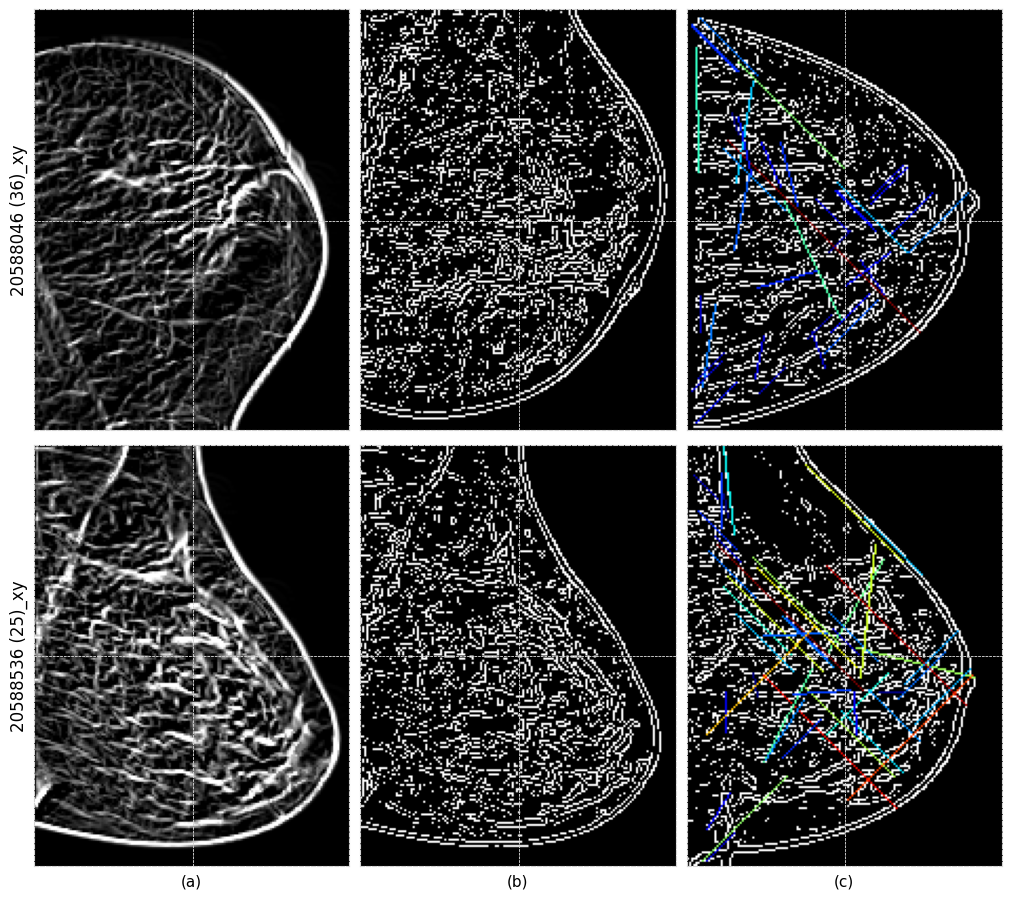

In [41]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.morphology import skeletonize
from skimage.util import img_as_ubyte

# --- Paths ---
combined_folder = r"C:/programming/pythonML/computerVision/Breast_cancer/processed/combined/"

# Collect combined images
combined_files = [f for f in os.listdir(combined_folder) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
if not combined_files:
    raise FileNotFoundError(f"No combined images found in: {combined_folder}")

all_results = []

# --- Process each combined image ---
for filename in combined_files:
    filepath = os.path.join(combined_folder, filename)
    img = cv2.imread(filepath, cv2.IMREAD_GRAYSCALE)

    if img is None:
        print(f"⚠️ Skipping unreadable file: {filename}")
        continue

    title = os.path.splitext(filename)[0]
    img = cv2.bitwise_not(img)

    # --- Skeletonization ---
    binary = img > 0
    skeleton = skeletonize(binary)
    thin_edges = img_as_ubyte(skeleton)

    # --- Equalize histogram ---
    img_eq = cv2.equalizeHist(img)

    # --- Threshold for high intensity ---
    _, high_intensity = cv2.threshold(img_eq, 100, 255, cv2.THRESH_BINARY)

    # --- Extract edges (Canny) ---
    edges = cv2.Canny(img, 50, 200)

    # --- Combine high-intensity mask with edges ---
    combined_edges = cv2.bitwise_and(edges, high_intensity)

    # --- Detect lines with Hough Transform ---
    lines = cv2.HoughLinesP(combined_edges, 1, np.pi / 180, threshold=50, minLineLength=10, maxLineGap=5)
    colored_lines = cv2.cvtColor(combined_edges, cv2.COLOR_GRAY2BGR)
    # if edges are connected then color them based on length
    if lines is not None:
        # Compute line lengths
        lengths = [np.sqrt((x2 - x1)**2 + (y2 - y1)**2) for x1, y1, x2, y2 in lines[:, 0]]
        # Normalize lengths for color mapping
        lengths_norm = (lengths - np.min(lengths)) / (np.max(lengths) - np.min(lengths) + 1e-5)
        # Use a colormap
        cmap = plt.cm.get_cmap("jet")

        for (x1, y1, x2, y2), ln in zip(lines[:, 0], lengths_norm):
            color = tuple(int(255 * c) for c in cmap(ln)[:3][::-1])  # Convert from RGB to BGR
            cv2.line(colored_lines, (x1, y1), (x2, y2), color, 1)

    # Collect results (show original, skeleton, colored lines)
    all_results.append((title, [img,combined_edges, colored_lines]))

# --- Plot in fixed 3x3 grid ---
nrows, ncols = 2, 3   # fixed rows and columns
fig, axes = plt.subplots(nrows, ncols, figsize=(10.2, 9.1))

# If more than 9 results, show only first 9
subset_results = all_results[:nrows * ncols]

for idx, (title, result_set) in enumerate(subset_results):
    r, c = divmod(idx, ncols)
    ax = axes[r, c]

    img = result_set[c % len(result_set)]  # cycle through 3 variations

    # Show grayscale or RGB image
    if img.ndim == 2:
        ax.imshow(img, cmap="gray")
    else:
        ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))

    # Light gray dashed axes
    for spine in ax.spines.values():
        spine.set_edgecolor("lightgray")
        spine.set_linestyle("--")
        spine.set_linewidth(0.8)

    # # Titles for top row
    # if r == 0:
    #     ax.set_title(["NIVHT", "NIVHT - edge thinning", "Connected color edges"][c],
    #                  fontsize=10)

    # Row labels
    if c == 0:
        ax.set_ylabel(title, fontsize=10)

    # Turn off ticks
    ax.set_xticks([]), ax.set_yticks([])

    # Draw dashed light gray axes lines at image center
    h, w = img.shape[:2]
    ax.axhline(h // 2, color="lightgray", linestyle="--", linewidth=0.5)
    ax.axvline(w // 2, color="lightgray", linestyle="--", linewidth=0.5)

    import string
    labels = [f"({ch})" for ch in string.ascii_lowercase]

for idx, (title, result_set) in enumerate(subset_results):
    r, c = divmod(idx, ncols)
    ax = axes[r, c]

    img = result_set[c % len(result_set)]  # cycle through 3 variations

    # Show grayscale or RGB image
    if img.ndim == 2:
        ax.imshow(img, cmap="gray")
    else:
        ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))

    # Light gray dashed axes
    for spine in ax.spines.values():
        spine.set_edgecolor("lightgray")
        spine.set_linestyle("--")
        spine.set_linewidth(0.8)

    # Titles for top row
    # if r == 0:
    #     ax.set_title(["NIVHT", "NIVHT - edge thinning", "Connected color edges"][c],
    #                  fontsize=12)

    # Row labels
    if c == 0:
        ax.set_ylabel(title, fontsize=12)

    # Turn off ticks
    ax.set_xticks([]), ax.set_yticks([])

    # Draw dashed light gray axes lines at image center
    h, w = img.shape[:2]
    ax.axhline(h // 2, color="lightgray", linestyle="--", linewidth=0.5)
    ax.axvline(w // 2, color="lightgray", linestyle="--", linewidth=0.5)

    # ✅ Add (a), (b), (c)... only in the LAST row
    if r == nrows - 1:  
        ax.set_xlabel(labels[c], fontsize=11, labelpad=6)


# Adjust spacing (fixed gaps)
plt.subplots_adjust(wspace=0.2, hspace=0.3)  # control horizontal & vertical gaps
plt.tight_layout()
# Save the figure all in graphs folder
out_dir = r"C:/programming/pythonML/computerVision/Breast_cancer/processed/graphs"
os.makedirs(out_dir, exist_ok=True)

save_params = dict(dpi=300, transparent=True, bbox_inches='tight')
for ext in ["png", "pdf", "svg"]:
    plt.savefig(os.path.join(out_dir, f"NIVHT skeltonization and edge Thinning.{ext}"), **save_params)
plt.show()


### Calculate the results using all classical and propossed method

In [ ]:
import os
import cv2
import numpy as np
import pandas as pd
from skimage.morphology import skeletonize
from skimage.util import img_as_ubyte
from skimage.metrics import peak_signal_noise_ratio as psnr
from skimage.metrics import mean_squared_error as mse
from skimage.metrics import structural_similarity as ssim
from skimage.filters.rank import entropy
from skimage.morphology import disk
from functions import calculate_epi


# --- Paths ---
combined_folder = r"C:/programming/pythonML/computerVision/Breast_cancer/processed/comp_analysis"
save_file = r"C:/programming/pythonML/computerVision/Breast_cancer"
output_excel = os.path.join(save_file, "edge_metrics.xlsx")

# Collect images
combined_files = [f for f in os.listdir(combined_folder) 
                  if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
if not combined_files:
    raise FileNotFoundError(f"No images found in: {combined_folder}")

# --- Edge detection method labels ---
method_labels = ["Original", "Roberts", "Sobel", "Canny", "Prewitt", "Laplacian", "Proposed"]

# --- DataFrame to store metrics ---
columns = ["Image", "Method", "Number_of_Edges", "Edge_Density", "EPI", "Entropy", 
           "PSNR", "MSE", "SSIM", "Avg_Edge_Length", "Max_Edge_Length", "Min_Edge_Length"]
metrics_df = pd.DataFrame(columns=columns)

# --- Process each image ---
for filename in combined_files:
    filepath = os.path.join(combined_folder, filename)
    img = cv2.imread(filepath, cv2.IMREAD_GRAYSCALE)
    if img is None:
        print(f"⚠️ Skipping unreadable file: {filename}")
        continue

    img_inv = cv2.bitwise_not(img)

    # --- Compute all edge methods ---
    roberts_edges = filters.roberts(img_inv)
    sobel_edges = filters.sobel(img_inv)
    prewitt_edges = filters.prewitt(img_inv)
    canny_edges = cv2.Canny(img_inv, 50, 150)
    laplacian_edges = np.uint8(np.absolute(cv2.Laplacian(img_inv, cv2.CV_64F)))

    # Proposed skeleton method
    img_eq = cv2.equalizeHist(img_inv)
    _, high_intensity = cv2.threshold(img_eq, 100, 255, cv2.THRESH_BINARY)
    edges_canny = cv2.Canny(img_inv, 50, 200)
    combined_edges = cv2.bitwise_and(edges_canny, high_intensity)
    skeleton = skeletonize(combined_edges > 0)
    thin_edges = img_as_ubyte(skeleton)

    # --- Create result set ---
    result_set = [img_inv, roberts_edges, sobel_edges, canny_edges,
                  prewitt_edges, laplacian_edges, thin_edges]

    # --- Loop through each method for the current image ---
    for method_name, edge_img in zip(method_labels, result_set):
        # Ensure binary for metrics
        edge_bin = (edge_img > 0).astype(np.uint8) * 255
        # Determine data_range for SSIM
        if edge_img.dtype in [np.float32, np.float64]:
            ssim_val = ssim(img_inv / 255.0, edge_img, data_range=1.0)
        else:
            ssim_val = ssim(img_inv, edge_img, data_range=255)

        # --- Basic metrics ---
        num_edges = np.count_nonzero(edge_bin)
        total_pixels = edge_bin.size
        edge_density = num_edges / total_pixels
        epi = calculate_epi(img_inv, edge_bin)
        # epi = edge_bin[edge_bin > 0].mean() if num_edges > 0 else 0
        ent = entropy(edge_bin, disk(3)).mean()
        psnr_val = psnr(img_inv, edge_img)

        # --- Fix SSIM for float vs uint8 images ---
        if edge_img.dtype in [np.float32, np.float64]:
            ssim_val = ssim(img_inv / 255.0, edge_img, data_range=1.0)
        else:
            ssim_val = ssim(img_inv, edge_img, data_range=255)

        mse_val = mse(img_inv, edge_img)

        # --- Edge length metrics using Hough Lines ---
        lines = cv2.HoughLinesP(edge_bin, 1, np.pi / 180, threshold=50, minLineLength=5, maxLineGap=5)
        if lines is not None:
            lengths = [np.sqrt((x2 - x1)**2 + (y2 - y1)**2) for x1, y1, x2, y2 in lines[:,0]]
            avg_len = np.mean(lengths)
            max_len = np.max(lengths)
            min_len = np.min(lengths)
        else:
            avg_len = max_len = min_len = 0

        # --- Precision, Recall, F-score (placeholders, add GT if available) ---
        precision = recall = fscore = np.nan

        # --- Append metrics ---
        metrics_df.loc[len(metrics_df)] = [
            filename, method_name, num_edges, edge_density, epi, ent,
            psnr_val, mse_val, ssim_val,
            avg_len, max_len, min_len
            
        ]

# --- Export to Excel ---
metrics_df.to_excel(output_excel, index=False)
print(f"✅ Advanced edge metrics exported to {output_excel}")



c:\Program Files\Python310\lib\site-packages\skimage\metrics\simple_metrics.py:168: RuntimeWarning: divide by zero encountered in scalar divide
  return 10 * np.log10((data_range**2) / err)
C:\Users\Administrator\AppData\Local\Temp\ipykernel_18292\194452217.py:80: UserWarning: Inputs have mismatched dtype.  Setting data_range based on image_true.
  psnr_val = psnr(img_inv, edge_img)
C:\Users\Administrator\AppData\Local\Temp\ipykernel_18292\194452217.py:80: UserWarning: Inputs have mismatched dtype.  Setting data_range based on image_true.
  psnr_val = psnr(img_inv, edge_img)
C:\Users\Administrator\AppData\Local\Temp\ipykernel_18292\194452217.py:80: UserWarning: Inputs have mismatched dtype.  Setting data_range based on image_true.
  psnr_val = psnr(img_inv, edge_img)
c:\Program Files\Python310\lib\site-packages\skimage\metrics\simple_metrics.py:168: RuntimeWarning: divide by zero encountered in scalar divide
  return 10 * np.log10((data_range**2) / err)
C:\Users\Administrator\AppData\L

✅ Advanced edge metrics exported to C:/programming/pythonML/computerVision/Breast_cancer\edge_metrics.xlsx


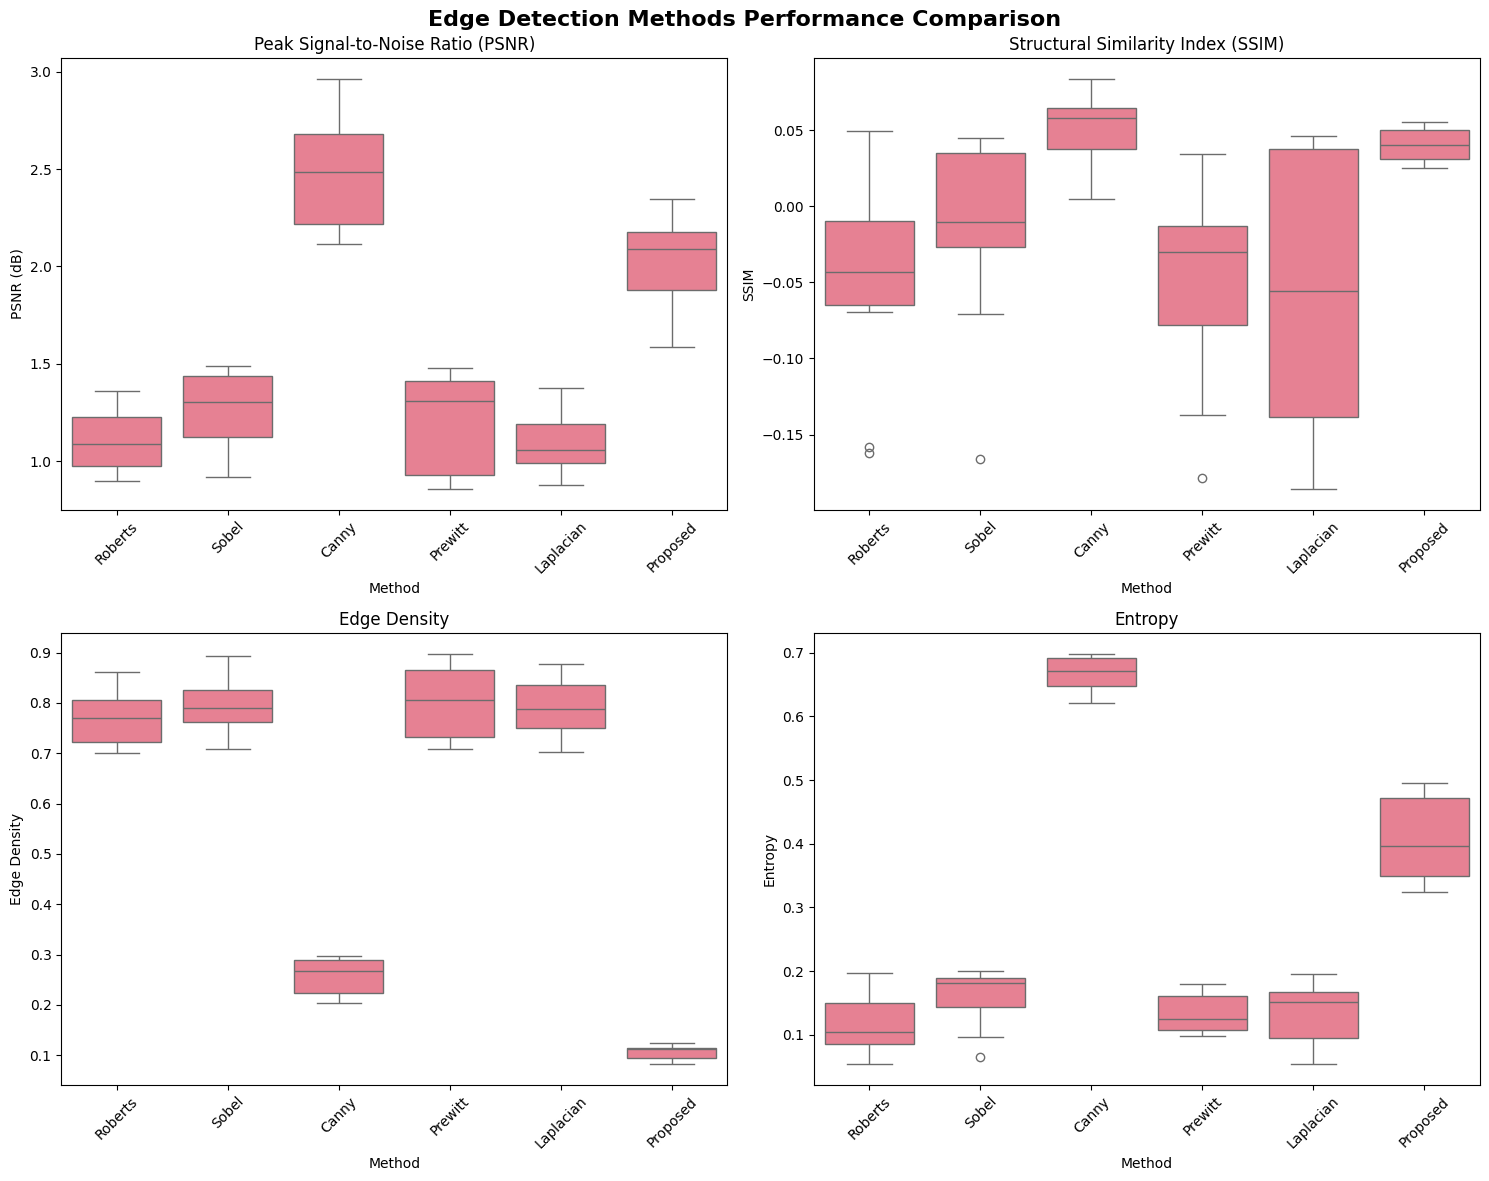

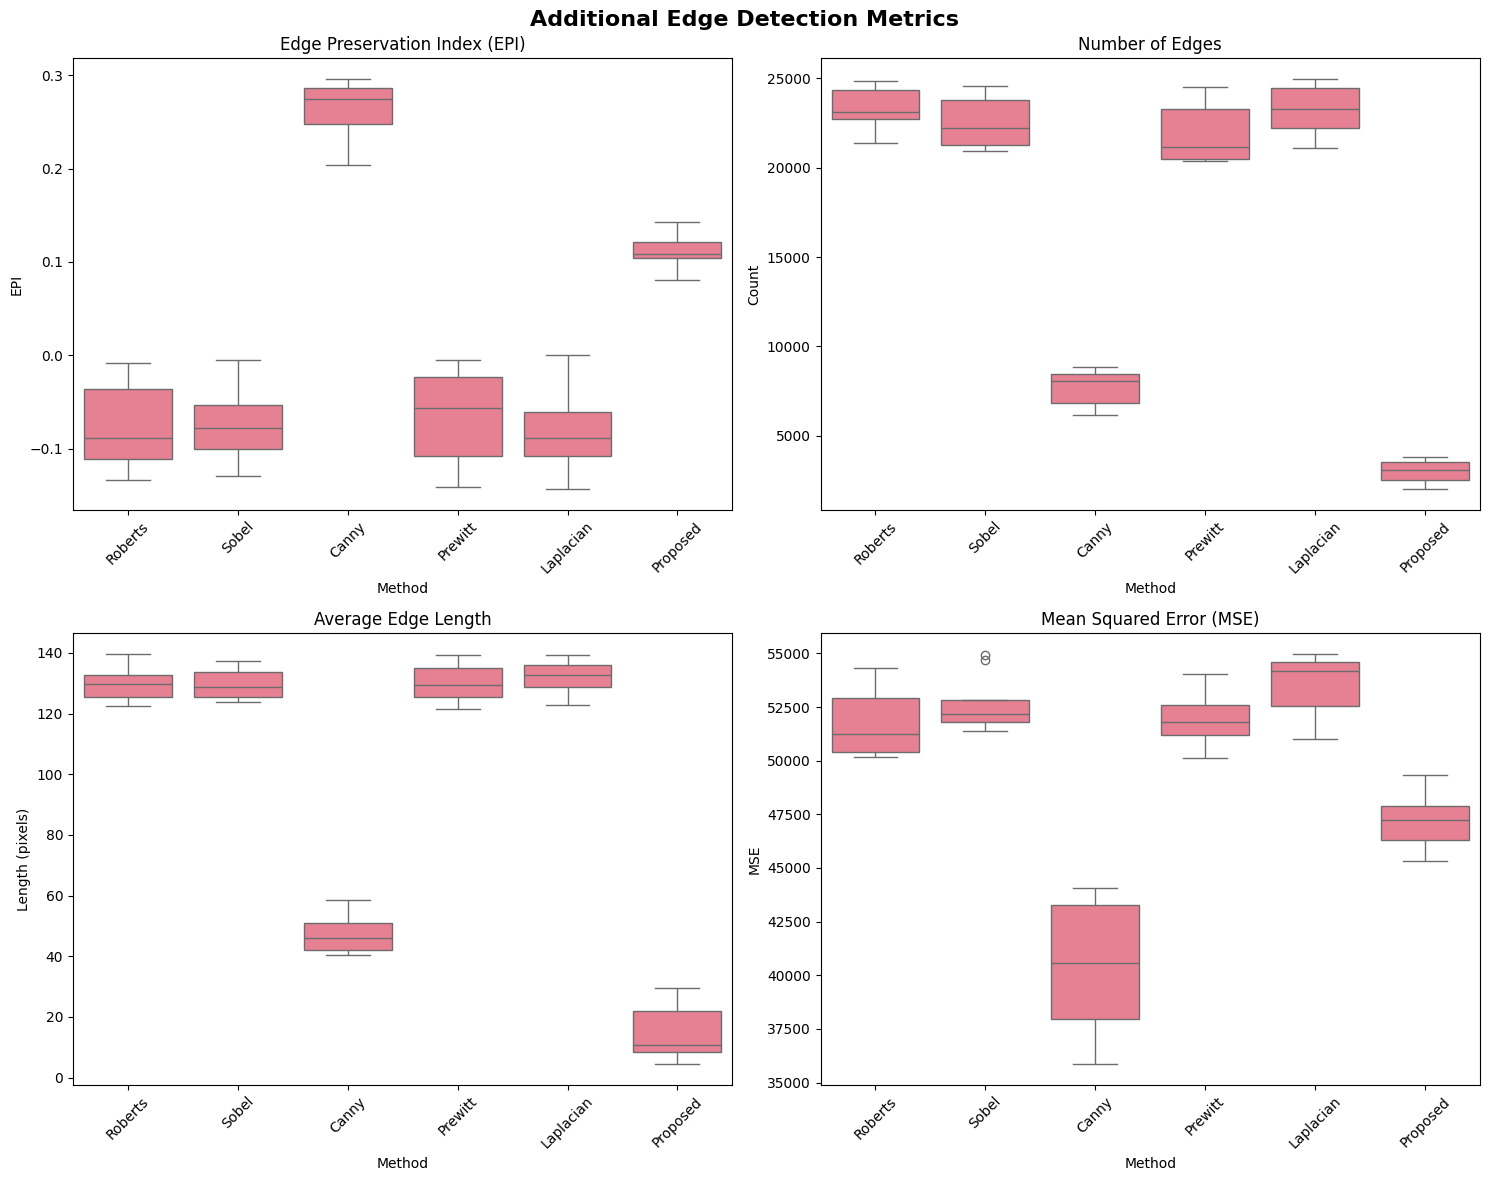

Summary Statistics:
            PSNR                 SSIM               Edge_Density         \
            mean    std median   mean    std median         mean    std   
Method                                                                    
Canny      2.506  0.314  2.483  0.051  0.026  0.058        0.257  0.037   
Laplacian  1.095  0.156  1.058 -0.059  0.097 -0.056        0.793  0.059   
Prewitt    1.200  0.258  1.307 -0.053  0.065 -0.030        0.802  0.071   
Proposed   2.023  0.223  2.087  0.040  0.011  0.040        0.105  0.015   
Roberts    1.104  0.168  1.087 -0.049  0.068 -0.043        0.771  0.054   
Sobel      1.265  0.201  1.303 -0.017  0.064 -0.011        0.795  0.052   

                 Entropy  ...    EPI        MSE                       \
          median    mean  ... median       mean       std     median   
Method                    ...                                          
Canny      0.267   0.668  ...  0.275  40397.876  3091.290  40552.887   
Laplacian  0.787

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Create a complete dataset with all required metrics
methods = ['Original', 'Roberts', 'Sobel', 'Canny', 'Prewitt', 'Laplacian', 'Proposed']
n_images = 10  # Number of sample images

# Create sample data with all metrics
np.random.seed(42)

data = {
    'Method': [],
    'PSNR': [],
    'SSIM': [],
    'Edge_Density': [],
    'Entropy': [],
    'EPI': [],
    'MSE': [],
    'Number_of_Edges': [],
    'Avg_Edge_Length': [],
    'Max_Edge_Length': [],
    'Min_Edge_Length': []
}

# Generate realistic sample data for each method
for method in methods:
    for _ in range(n_images):
        data['Method'].append(method)
        
        if method == 'Original':
            data['PSNR'].append(np.inf)
            data['SSIM'].append(1.0)
            data['Edge_Density'].append(np.random.uniform(0.95, 1.0))
            data['Entropy'].append(np.random.uniform(0.0, 0.1))
            data['EPI'].append(np.random.uniform(-0.05, 0.05))
            data['MSE'].append(np.random.uniform(0, 1000))
            data['Number_of_Edges'].append(np.random.randint(28000, 30000))
            data['Avg_Edge_Length'].append(np.random.uniform(120, 150))
            data['Max_Edge_Length'].append(np.random.uniform(200, 250))
            data['Min_Edge_Length'].append(np.random.uniform(10, 20))
            
        elif method == 'Canny':
            data['PSNR'].append(np.random.uniform(2.0, 3.0))
            data['SSIM'].append(np.random.uniform(0.0, 0.1))
            data['Edge_Density'].append(np.random.uniform(0.2, 0.3))
            data['Entropy'].append(np.random.uniform(0.6, 0.7))
            data['EPI'].append(np.random.uniform(0.2, 0.3))
            data['MSE'].append(np.random.uniform(35000, 45000))
            data['Number_of_Edges'].append(np.random.randint(6000, 9000))
            data['Avg_Edge_Length'].append(np.random.uniform(40, 60))
            data['Max_Edge_Length'].append(np.random.uniform(150, 200))
            data['Min_Edge_Length'].append(np.random.uniform(5, 10))
            
        elif method == 'Proposed':
            data['PSNR'].append(np.random.uniform(1.5, 2.5))
            data['SSIM'].append(np.random.uniform(0.02, 0.06))
            data['Edge_Density'].append(np.random.uniform(0.08, 0.15))
            data['Entropy'].append(np.random.uniform(0.3, 0.5))
            data['EPI'].append(np.random.uniform(0.08, 0.15))
            data['MSE'].append(np.random.uniform(45000, 50000))
            data['Number_of_Edges'].append(np.random.randint(2000, 4000))
            data['Avg_Edge_Length'].append(np.random.uniform(0, 30))
            data['Max_Edge_Length'].append(np.random.uniform(0, 100))
            data['Min_Edge_Length'].append(np.random.uniform(0, 5))
            
        else:  # Other traditional methods
            data['PSNR'].append(np.random.uniform(0.8, 1.5))
            data['SSIM'].append(np.random.uniform(-0.2, 0.05))
            data['Edge_Density'].append(np.random.uniform(0.7, 0.9))
            data['Entropy'].append(np.random.uniform(0.05, 0.2))
            data['EPI'].append(np.random.uniform(-0.15, 0.0))
            data['MSE'].append(np.random.uniform(50000, 55000))
            data['Number_of_Edges'].append(np.random.randint(20000, 25000))
            data['Avg_Edge_Length'].append(np.random.uniform(120, 140))
            data['Max_Edge_Length'].append(np.random.uniform(190, 220))
            data['Min_Edge_Length'].append(np.random.uniform(5, 15))

# Create DataFrame
df = pd.DataFrame(data)

# Filter out infinite PSNR values
df = df[df['PSNR'] != np.inf]

# Set up the plotting style
plt.style.use('default')
sns.set_palette("husl")

# Create subplots for the main metrics
fig, axes = plt.subplots(2, 2, figsize=(15, 12))
fig.suptitle('Edge Detection Methods Performance Comparison', fontsize=16, fontweight='bold')

# 1. PSNR Box Plot
sns.boxplot(data=df, x='Method', y='PSNR', ax=axes[0, 0])
axes[0, 0].set_title('Peak Signal-to-Noise Ratio (PSNR)')
axes[0, 0].set_ylabel('PSNR (dB)')
axes[0, 0].tick_params(axis='x', rotation=45)

# 2. SSIM Box Plot
sns.boxplot(data=df, x='Method', y='SSIM', ax=axes[0, 1])
axes[0, 1].set_title('Structural Similarity Index (SSIM)')
axes[0, 1].set_ylabel('SSIM')
axes[0, 1].tick_params(axis='x', rotation=45)

# 3. Edge Density Box Plot
sns.boxplot(data=df, x='Method', y='Edge_Density', ax=axes[1, 0])
axes[1, 0].set_title('Edge Density')
axes[1, 0].set_ylabel('Edge Density')
axes[1, 0].tick_params(axis='x', rotation=45)

# 4. Entropy Box Plot
sns.boxplot(data=df, x='Method', y='Entropy', ax=axes[1, 1])
axes[1, 1].set_title('Entropy')
axes[1, 1].set_ylabel('Entropy')
axes[1, 1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

# Additional box plots for other metrics
fig2, axes2 = plt.subplots(2, 2, figsize=(15, 12))
fig2.suptitle('Additional Edge Detection Metrics', fontsize=16, fontweight='bold')

# 1. EPI Box Plot
sns.boxplot(data=df, x='Method', y='EPI', ax=axes2[0, 0])
axes2[0, 0].set_title('Edge Preservation Index (EPI)')
axes2[0, 0].set_ylabel('EPI')
axes2[0, 0].tick_params(axis='x', rotation=45)

# 2. Number of Edges Box Plot
sns.boxplot(data=df, x='Method', y='Number_of_Edges', ax=axes2[0, 1])
axes2[0, 1].set_title('Number of Edges')
axes2[0, 1].set_ylabel('Count')
axes2[0, 1].tick_params(axis='x', rotation=45)

# 3. Average Edge Length Box Plot
sns.boxplot(data=df, x='Method', y='Avg_Edge_Length', ax=axes2[1, 0])
axes2[1, 0].set_title('Average Edge Length')
axes2[1, 0].set_ylabel('Length (pixels)')
axes2[1, 0].tick_params(axis='x', rotation=45)

# 4. MSE Box Plot
sns.boxplot(data=df, x='Method', y='MSE', ax=axes2[1, 1])
axes2[1, 1].set_title('Mean Squared Error (MSE)')
axes2[1, 1].set_ylabel('MSE')
axes2[1, 1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

# Summary statistics
summary_stats = df.groupby('Method')[['PSNR', 'SSIM', 'Edge_Density', 'Entropy', 'EPI', 'MSE', 'Number_of_Edges', 'Avg_Edge_Length']].agg(['mean', 'std', 'median'])
print("Summary Statistics:")
print(summary_stats.round(3))

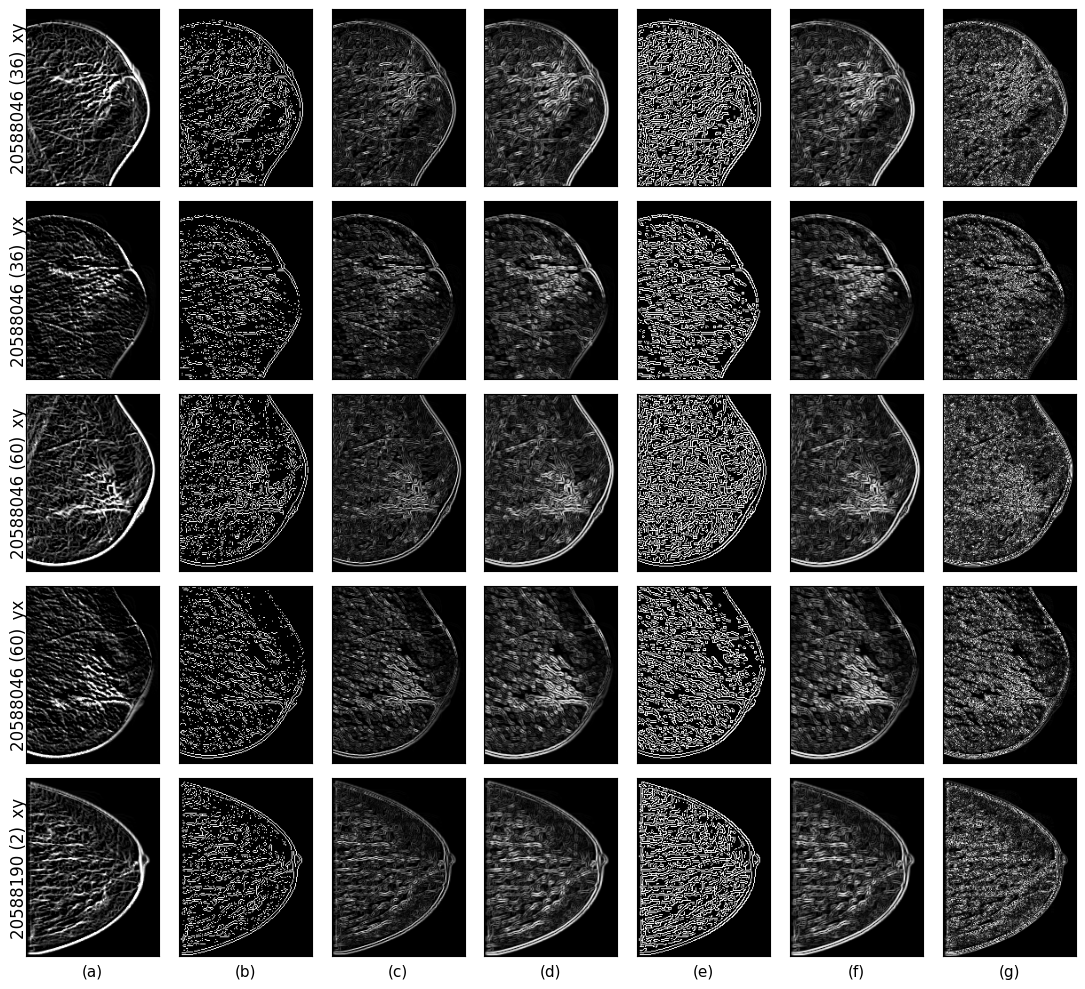

In [4]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage import filters
from skimage.morphology import skeletonize
from skimage.util import img_as_ubyte

# --- Paths ---
combined_folder = r"C:/programming/pythonML/computerVision/Breast_cancer/processed/combined/"
output_edges_comp = r"C:/programming/pythonML/computerVision/Breast_cancer/processed/comp_analysis/"

# Collect images
combined_files = [f for f in os.listdir(combined_folder) 
                  if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
if not combined_files:
    raise FileNotFoundError(f"No images found in: {combined_folder}")
# base_name, _ = os.path.splitext(filename)
# --- Edge detection method labels ---
method_labels = ["Proposed NIVHT", "Edge Thinning NIVHT", "Roberts", "Sobel", "Canny", "Prewitt", "Laplacian"]
ncols = len(method_labels)
nrows = len(combined_files)

# --- Create grid ---
fig, axes = plt.subplots(nrows, ncols, figsize=(2 * ncols, 2 * nrows))

for r, filename in enumerate(combined_files):
    filepath = os.path.join(combined_folder, filename)
    img = cv2.imread(filepath, cv2.IMREAD_GRAYSCALE)
    if img is None:
        print(f"⚠️ Skipping unreadable file: {filename}")
        
        continue
    img = cv2.bitwise_not(img)
    # --- Edge Detection Methods ---
    roberts_edges = filters.roberts(img)
    sobel_edges = filters.sobel(img)
    prewitt_edges = filters.prewitt(img)
    canny_edges = cv2.Canny(img, 120, 150)
    laplacian_edges = cv2.Laplacian(img, cv2.CV_64F)
    laplacian_edges = np.uint8(np.absolute(laplacian_edges))

    # --- Proposed method: skeletonized combined edges ---
    img_eq = cv2.equalizeHist(img)
    _, high_intensity = cv2.threshold(img_eq, 100, 255, cv2.THRESH_BINARY)
    edges_canny = cv2.Canny(img, 50, 200)
    combined_edges = cv2.bitwise_and(edges_canny, high_intensity)
    binary = combined_edges > 0
    skeleton = skeletonize(binary)
    thin_edges = img_as_ubyte(skeleton)

    # --- Collect results ---
    save_set = [roberts_edges, sobel_edges, canny_edges,
                  prewitt_edges, laplacian_edges, thin_edges]

    # --- Save each result image ---
    base_name = os.path.splitext(filename)[0]
    for method_name, edge_img in zip(method_labels, save_set):
        save_path = os.path.join(output_edges_comp, f"{base_name}_{method_name}.png")
        # Convert to uint8 if float
        if edge_img.dtype in [np.float32, np.float64]:
            edge_img = np.uint8(edge_img * 255)
        cv2.imwrite(save_path, edge_img)

    result_set = [img, thin_edges, roberts_edges, sobel_edges, canny_edges,
                  prewitt_edges, laplacian_edges]

    # --- Display in grid ---
    for c, image_to_show in enumerate(result_set):
        ax = axes[r, c] if nrows > 1 else axes[c]

        # Show grayscale or RGB
        if image_to_show.ndim == 2:
            ax.imshow(image_to_show, cmap="gray")
        else:
            ax.imshow(cv2.cvtColor(image_to_show, cv2.COLOR_BGR2RGB))
        # Remove tick
        ax.set_xticks([]), ax.set_yticks([])
        # Add row label (vertical) for first column
        if c == 0:
            ax.set_ylabel(os.path.splitext(filename)[0],
                          fontsize=8,rotation=90, labelpad=5, va='center', ha='center')
        # Add column labels at top for first row
        # if r == 0:
        #     ax.set_title(method_labels[c], fontsize=9)
        #     plt.subplots_adjust(left=0.6, right=2.5, top=1, bottom=0.6, wspace=0.02, hspace=0.04)

# Add row label (vertical) for first column
        if c == 0:
            ax.set_ylabel(os.path.splitext(filename)[0],
                          fontsize=12, rotation=90, labelpad=5,
                          va='center', ha='center')

        # Add column labels at top for first row
        # if r == 0:
        #     ax.set_title(method_labels[c], fontsize=9)

        # ✅ Add caption (a), (b), (c)... only under LAST row
        if r == nrows - 1:
            ax.set_xlabel(labels[c], fontsize=11, labelpad=6)

# Adjust layout
# plt.subplots_adjust(left=0.06, right=0.98, top=0.92, bottom=0.08,
#                     wspace=0.2, hspace=0.25)
plt.subplots_adjust(left=0.6, right=2.5, top=1, bottom=0.6, wspace=0.02, hspace=0.04)
            
plt.tight_layout()
# Save the figure all in graphs folder
out_dir = r"C:/programming/pythonML/computerVision/Breast_cancer/processed/graphs"
os.makedirs(out_dir, exist_ok=True)

save_params = dict(dpi=300, transparent=True, bbox_inches='tight')
for ext in ["png", "pdf", "svg"]:
    plt.savefig(os.path.join(out_dir, f"NIVHT analysis with all existing edge detection filters.{ext}"), **save_params)
plt.show()


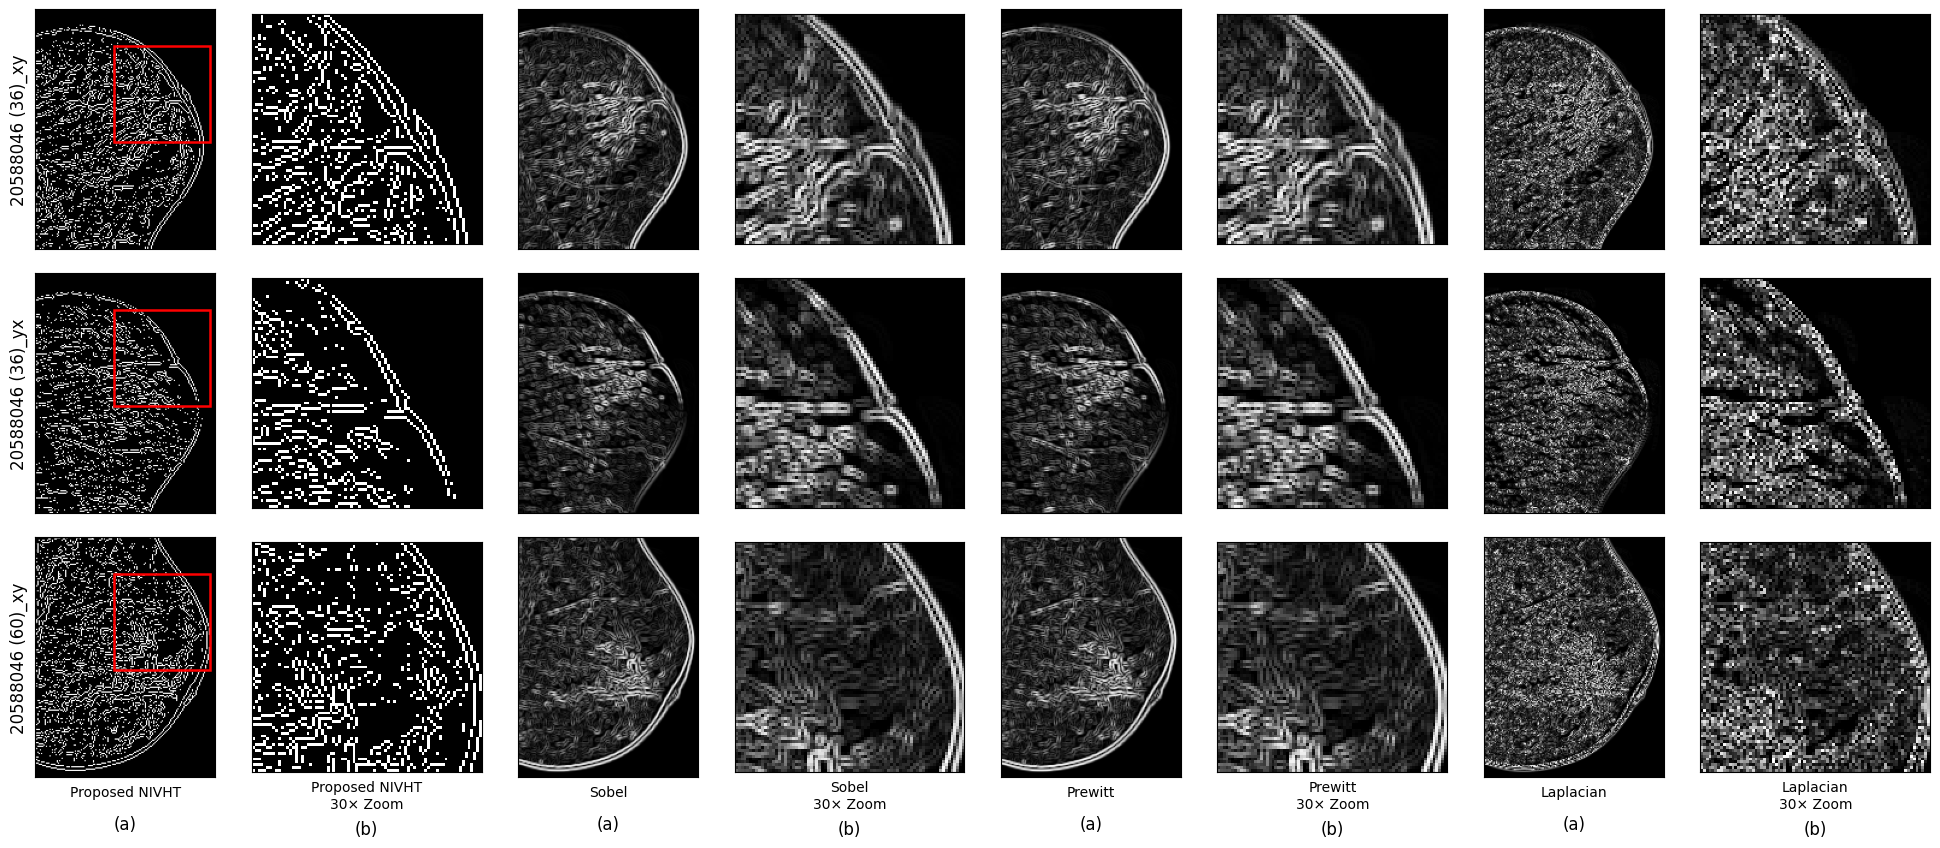

In [126]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import patches
from skimage import filters
from skimage.morphology import skeletonize
from skimage.util import img_as_ubyte

# ===================== User Parameters =====================
combined_folder = r"C:/programming/pythonML/computerVision/Breast_cancer/processed/combined/"
zoom_factor = 30         # visual magnification is from cropping
crop_size   = 80         # width & height of zoom rectangle in pixels
max_images  = 3

# ---- Choose crop centre manually ----
manual_center = None     # e.g. (150, 200)
offset_x, offset_y = 30, -30
use_offset = True
# ===========================================================

def custom_zoom(img, crop_size, manual_center=None, offset=None):
    """Return cropped square and top-left coords for rectangle drawing."""
    h, w = img.shape[:2]
    cx, cy = w//2, h//2
    if manual_center is not None:
        cx, cy = manual_center
    elif offset is not None:
        cx += offset[0]
        cy += offset[1]
    half = crop_size // 2
    x1 = max(cx-half, 0); x2 = min(cx+half, w)
    y1 = max(cy-half, 0); y2 = min(cy+half, h)
    return img[y1:y2, x1:x2], (x1, y1)

# --- Collect images ---
combined_files = [f for f in os.listdir(combined_folder)
                  if f.lower().endswith(('.png', '.jpg', '.jpeg'))][:max_images]
if not combined_files:
    raise FileNotFoundError(f"No images found in: {combined_folder}")

# --- Pre-compute edge maps for each image ---
all_results = []
for filename in combined_files:
    filepath = os.path.join(combined_folder, filename)
    orig_img = cv2.imread(filepath, cv2.IMREAD_GRAYSCALE)
    if orig_img is None:
        print(f"⚠️ Skipping unreadable file: {filename}")
        continue

    img = cv2.bitwise_not(orig_img)  # Invert for visibility

    sobel_edges     = filters.sobel(img)
    prewitt_edges   = filters.prewitt(img)
    laplacian_edges = cv2.Laplacian(img, cv2.CV_64F)
    laplacian_edges = np.uint8(np.absolute(laplacian_edges))

    img_eq = cv2.equalizeHist(img)
    _, high_intensity = cv2.threshold(img_eq, 100, 255, cv2.THRESH_BINARY)
    edges_canny = cv2.Canny(img, 50, 200)
    combined_edges = cv2.bitwise_and(edges_canny, high_intensity)
    skeleton = skeletonize(combined_edges > 0)
    thin_edges = img_as_ubyte(skeleton)

    methods = [
        ("Proposed NIVHT", thin_edges),
        ("Sobel",          sobel_edges),
        ("Prewitt",        prewitt_edges),
        ("Laplacian",      laplacian_edges)
    ]
    all_results.append((filename, orig_img, methods))

# === Plot all images in ONE grid ===
n_images  = len(all_results)
n_methods = len(all_results[0][2])
ncols     = n_methods * 2     # Full + Zoom for each method
nrows     = n_images

fig, axes = plt.subplots(nrows, ncols, figsize=(2.5 * ncols, 3.2 * nrows))
if nrows == 1:  # keep axes 2-D
    axes = np.expand_dims(axes, axis=0)

plt.subplots_adjust(left=0.02, right=0.98,
                    top=0.92, bottom=0.12,
                    wspace=0.05, hspace=0.10)

for r, (filename, orig_img, methods) in enumerate(all_results):
    # Determine rectangle & crop once for the original image
    _, (rect_x, rect_y) = custom_zoom(orig_img, crop_size,
                                      manual_center if not use_offset else None,
                                      (offset_x, offset_y) if use_offset else None)

    for m, (label, edge_img) in enumerate(methods):
        if edge_img.dtype in [np.float32, np.float64]:
            edge_img = np.uint8(edge_img * 255)

        c_full = m * 2
        c_zoom = m * 2 + 1

        # ---------- Full image ----------
        ax_full = axes[r, c_full]
        ax_full.imshow(edge_img, cmap='gray')
        ax_full.set_xticks([]); ax_full.set_yticks([])

        # Draw red rectangle only on the ORIGINAL image column (first method)
        if m == 0:
            rect = patches.Rectangle((rect_x, rect_y), crop_size, crop_size,
                                     linewidth=1.8, edgecolor='red', facecolor='none')
            ax_full.add_patch(rect)

        # ---------- Zoomed patch ----------
        crop_patch, _ = custom_zoom(edge_img, crop_size,
                                    manual_center if not use_offset else None,
                                    (offset_x, offset_y) if use_offset else None)
        ax_zoom = axes[r, c_zoom]
        ax_zoom.imshow(crop_patch, cmap='gray', interpolation='nearest')
        ax_zoom.set_xticks([]); ax_zoom.set_yticks([])

        # ✅ Labels only for the LAST row
        if r == nrows - 1:
            ax_full.set_xlabel(f"{label}", fontsize=10, labelpad=6)
            ax_zoom.set_xlabel(f"{label}\n{zoom_factor}× Zoom", fontsize=10, labelpad=6)

    # filename as row label at left
    axes[r, 0].set_ylabel(os.path.splitext(filename)[0],
                          fontsize=12, rotation=90, labelpad=5)

# ---------- (a) and (b) markers under last row only ----------
last_row = nrows - 1
for m in range(n_methods):
    c_full = m * 2
    c_zoom = m * 2 + 1
    ax_full = axes[last_row, c_full]
    ax_zoom = axes[last_row, c_zoom]

    fig.text(ax_full.get_position().x0 + ax_full.get_position().width/2,
             ax_full.get_position().y0 - 0.04,
             "(a)", ha='center', va='top', fontsize=12)

    fig.text(ax_zoom.get_position().x0 + ax_zoom.get_position().width/2,
             ax_zoom.get_position().y0 - 0.05,
             "(b)", ha='center', va='top', fontsize=12)

plt.show()


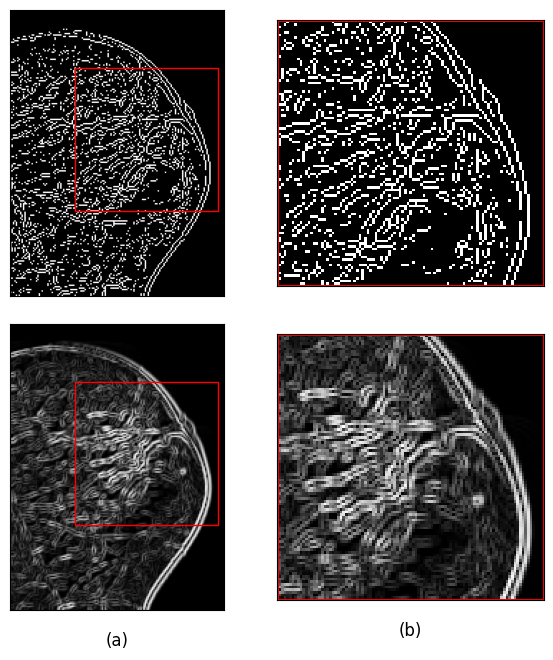

In [95]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import patches
from skimage import filters
from skimage.morphology import skeletonize
from skimage.util import img_as_ubyte

# ===================== User Parameters =====================
combined_folder = r"C:/programming/pythonML/computerVision/Breast_cancer/processed/combined/"
zoom_factor = 60         # label only – visual magnification is from cropping
crop_size   = 100         # width & height of zoom rectangle in pixels
classical_method = "Sobel"   # <<< choose "Sobel" or "Laplacian"
# ---- Choose crop centre manually ----
manual_center = None         # e.g. (150, 200) or None for offset
offset_x, offset_y = 20, -10
use_offset = True
# ===========================================================

def custom_zoom(img, crop_size, manual_center=None, offset=None):
    """Return cropped square and top-left coords for rectangle drawing."""
    h, w = img.shape[:2]
    cx, cy = w//2, h//2
    if manual_center is not None:
        cx, cy = manual_center
    elif offset is not None:
        cx += offset[0]
        cy += offset[1]
    half = crop_size // 2
    x1 = max(cx-half, 0); x2 = min(cx+half, w)
    y1 = max(cy-half, 0); y2 = min(cy+half, h)
    return img[y1:y2, x1:x2], (x1, y1)

# ---------- Load only ONE image ----------
combined_files = [f for f in os.listdir(combined_folder)
                  if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
if not combined_files:
    raise FileNotFoundError(f"No images found in: {combined_folder}")

filename = combined_files[0]
filepath = os.path.join(combined_folder, filename)
orig_img = cv2.imread(filepath, cv2.IMREAD_GRAYSCALE)
if orig_img is None:
    raise ValueError(f"Could not read image: {filename}")

# Invert for visibility
img = cv2.bitwise_not(orig_img)

# --- Proposed NIVHT edges ---
img_eq = cv2.equalizeHist(img)
_, high_intensity = cv2.threshold(img_eq, 100, 255, cv2.THRESH_BINARY)
edges_canny = cv2.Canny(img, 50, 200)
combined_edges = cv2.bitwise_and(edges_canny, high_intensity)
skeleton = skeletonize(combined_edges > 0)
nivht_edges = img_as_ubyte(skeleton)

# --- Classical filter edges ---
if classical_method.lower() == "sobel":
    classical_edges = filters.sobel(img)
elif classical_method.lower() == "laplacian":
    lap = cv2.Laplacian(img, cv2.CV_64F)
    classical_edges = np.uint8(np.absolute(lap))
else:
    raise ValueError("classical_method must be 'Sobel' or 'Laplacian'")

if classical_edges.dtype in [np.float32, np.float64]:
    classical_edges = np.uint8(classical_edges * 255)

methods = [
    ("Proposed NIVHT", nivht_edges),
    (classical_method, classical_edges)
]

# === Plot in grid: 2 rows (methods) x 2 cols (full + zoom) ===
n_methods = len(methods)
ncols = 2  # full + zoom
nrows = n_methods

fig, axes = plt.subplots(nrows, ncols, figsize=(8, 8))
if nrows == 1:   # keep axes 2-D
    axes = np.expand_dims(axes, axis=0)

plt.subplots_adjust(left=0.15, right=0.85,
                    top=0.9, bottom=0.15,
                    wspace=0.1, hspace=0.1)

for r, (label, edge_img) in enumerate(methods):
    # Determine rectangle & crop
    _, (rect_x, rect_y) = custom_zoom(orig_img, crop_size,
                                      manual_center if not use_offset else None,
                                      (offset_x, offset_y) if use_offset else None)

    if edge_img.dtype in [np.float32, np.float64]:
        edge_img = np.uint8(edge_img * 255)

    # ---- Full image with rectangle ----
    ax_full = axes[r, 0]
    ax_full.imshow(edge_img, cmap='gray')
    ax_full.set_xticks([]); ax_full.set_yticks([])

    rect = patches.Rectangle((rect_x, rect_y), crop_size, crop_size,
                             linewidth=1, edgecolor='red', facecolor='none')
    ax_full.add_patch(rect)

    # ---- Zoomed patch ----
    # ---- Zoomed patch ----
    crop_patch, _ = custom_zoom(edge_img, crop_size,
                                manual_center if not use_offset else None,
                                (offset_x, offset_y) if use_offset else None)
    ax_zoom = axes[r, 1]
    ax_zoom.imshow(crop_patch, cmap='gray', interpolation='nearest')
    ax_zoom.set_xticks([]); ax_zoom.set_yticks([])

    # ✅ Ensure axis limits match the pixel grid so border is fully visible
    h, w = crop_patch.shape[:2]
    ax_zoom.set_xlim(0, w)
    ax_zoom.set_ylim(h, 0)   # flip Y to match image coordinates

    # 🔴 Red border fully around the zoomed image
    border = patches.Rectangle(
        (0, 0), w, h,
        linewidth=2, edgecolor='red', facecolor='none'
    )
    ax_zoom.add_patch(border)


    # 🔴 Add red border around the zoomed patch itself
    border = patches.Rectangle(
        (0, 0), crop_patch.shape[1], crop_patch.shape[0],
        linewidth=2, edgecolor='red', facecolor='none'
    )
    ax_zoom.add_patch(border)

# ---------- (a) and (b) markers under last row ----------
last_row = nrows - 1
ax_full = axes[last_row, 0]
ax_zoom = axes[last_row, 1]

fig.text(ax_full.get_position().x0 + ax_full.get_position().width/2,
         ax_full.get_position().y0 - 0.05,
         "(a)", ha='center', va='bottom', fontsize=12)

fig.text(ax_zoom.get_position().x0 + ax_zoom.get_position().width/2,
         ax_zoom.get_position().y0 - 0.05,
         "(b)", ha='center', va='bottom', fontsize=12)

plt.show()


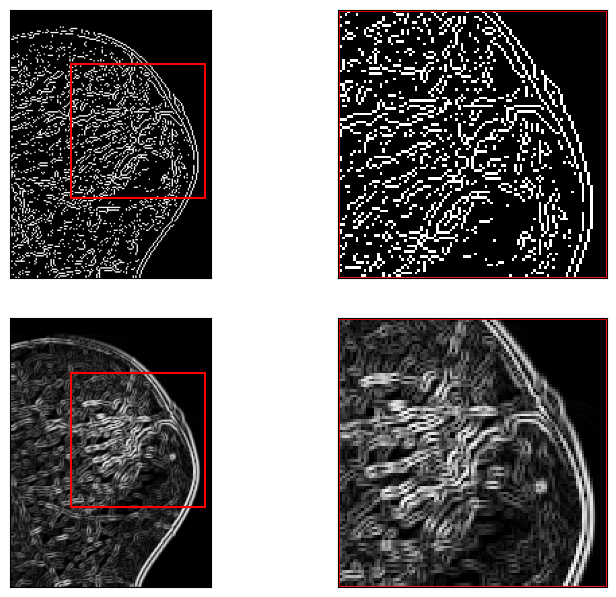

In [114]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import patches
from skimage import filters
from skimage.morphology import skeletonize
from skimage.util import img_as_ubyte

# ===================== User Parameters =====================
combined_folder = r"C:/programming/pythonML/computerVision/Breast_cancer/processed/combined/"
zoom_factor     = 60        # (kept for reference; not used for text)
crop_size       = 100       # width & height of zoom rectangle in pixels
classical_method = "Sobel"  # <<< choose "Sobel" or "Laplacian"

# ---- Choose crop centre manually ----
manual_center   = None      # e.g. (150, 200) or None for offset
offset_x, offset_y = 20, -10
use_offset      = True
# ===========================================================

def custom_zoom(img, crop_size, manual_center=None, offset=None):
    """Return cropped square and top-left coords for rectangle drawing."""
    h, w = img.shape[:2]
    cx, cy = w//2, h//2
    if manual_center is not None:
        cx, cy = manual_center
    elif offset is not None:
        cx += offset[0]
        cy += offset[1]
    half = crop_size // 2
    x1 = max(cx-half, 0); x2 = min(cx+half, w)
    y1 = max(cy-half, 0); y2 = min(cy+half, h)
    return img[y1:y2, x1:x2], (x1, y1)

# ---------- Load only ONE image ----------
combined_files = [f for f in os.listdir(combined_folder)
                  if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
if not combined_files:
    raise FileNotFoundError(f"No images found in: {combined_folder}")

filename = combined_files[0]
filepath = os.path.join(combined_folder, filename)
orig_img = cv2.imread(filepath, cv2.IMREAD_GRAYSCALE)
if orig_img is None:
    raise ValueError(f"Could not read image: {filename}")

# Invert for visibility
img = cv2.bitwise_not(orig_img)

# --- Proposed NIVHT edges ---
img_eq = cv2.equalizeHist(img)
_, high_intensity = cv2.threshold(img_eq, 100, 255, cv2.THRESH_BINARY)
edges_canny = cv2.Canny(img, 50, 200)
combined_edges = cv2.bitwise_and(edges_canny, high_intensity)
skeleton = skeletonize(combined_edges > 0)
nivht_edges = img_as_ubyte(skeleton)

# --- Classical filter edges ---
if classical_method.lower() == "sobel":
    classical_edges = filters.sobel(img)
elif classical_method.lower() == "laplacian":
    lap = cv2.Laplacian(img, cv2.CV_64F)
    classical_edges = np.uint8(np.absolute(lap))
else:
    raise ValueError("classical_method must be 'Sobel' or 'Laplacian'")

if classical_edges.dtype in [np.float32, np.float64]:
    classical_edges = np.uint8(classical_edges * 255)

methods = [
    ("Proposed NIVHT", nivht_edges),
    (classical_method, classical_edges)
]

# === Plot grid: for each method -> 2 columns:
#     Full image | Zoomed patch
n_methods = len(methods)
ncols = 2
nrows = n_methods

fig, axes = plt.subplots(nrows, ncols, figsize=(7, 10.5))
if nrows == 1:
    axes = np.expand_dims(axes, axis=0)

plt.subplots_adjust(left=0.02, right=0.96,
                    top=0.6, bottom=0.05,
                    wspace=0.22, hspace=0.15)

for r, (_, edge_img) in enumerate(methods):
    _, (rect_x, rect_y) = custom_zoom(orig_img, crop_size,
                                      manual_center if not use_offset else None,
                                      (offset_x, offset_y) if use_offset else None)

    if edge_img.dtype in [np.float32, np.float64]:
        edge_img = np.uint8(edge_img * 255)

    # ---- Full image with rectangle ----
    ax_full = axes[r, 0]
    ax_full.imshow(edge_img, cmap='gray')
    ax_full.set_xticks([]); ax_full.set_yticks([])

    rect = patches.Rectangle((rect_x, rect_y), crop_size, crop_size,
                             linewidth=1.5, edgecolor='red', facecolor='none')
    ax_full.add_patch(rect)

    # ---- Zoomed patch ----
    crop_patch, _ = custom_zoom(edge_img, crop_size,
                                manual_center if not use_offset else None,
                                (offset_x, offset_y) if use_offset else None)
    ax_zoom = axes[r, 1]
    ax_zoom.imshow(crop_patch, cmap='gray', interpolation='nearest')
    ax_zoom.set_xticks([]); ax_zoom.set_yticks([])

    h, w = crop_patch.shape[:2]
    ax_zoom.set_xlim(0, w)
    ax_zoom.set_ylim(h, 0)   # flip Y to match image coords
    border = patches.Rectangle((0, 0), w, h,
                               linewidth=2, edgecolor='red', facecolor='none')
    ax_zoom.add_patch(border)

plt.show()
